In [1]:
# Verify the versions
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.__version__, np.__version__

('2.3.3', '2.4.6')

In [2]:
# Enable logging.
import logging
from pathlib import Path

logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
    handlers=[
        logging.StreamHandler(),
        logging.FileHandler("pipeline.log", encoding="utf-8")
    ],
    force=True
)

logger.info("Logging has been enabled.")

2026-10-10 10:28:36,572 | INFO | __main__ | Logging has been enabled.


In [6]:
# 1.	Load the raw CSV file 
def load_raw_data(file_path):
    data = pd.read_csv(file_path, keep_default_na=False)

    logger.info(
        "Raw CSV has been loaded succesfully: %s rows and %s columns.",
        data.shape[0],
        data.shape[1]
    )

    return data


raw_path = Path("../part1_data_analytics/Metro_Interstate_Traffic_Volume.csv")

try:
    raw_data = load_raw_data(raw_path)

except (OSError, UnicodeError, pd.errors.ParserError,
        pd.errors.EmptyDataError):
    raw_data = None
    logger.error("Could not load the raw CSV", exc_info=True)

2026-10-10 00:19:48,334 | INFO | __main__ | Raw CSV has been loaded succesfully: 48204 rows and 9 columns.


In [7]:
# Columns headers from CSV file
EXPECTED_COLUMNS = [
    "holiday",
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "weather_main",
    "weather_description",
    "date_time",
    "traffic_volume"
]


# Check the columns before cleaning the data.

def validate_schema(data):
    missing_columns = [
        column for column in EXPECTED_COLUMNS
        if column not in data.columns
    ]

    # Stop validation if any required column is missing.
    if missing_columns:
        raise ValueError(
            f"Required columns are missing: {missing_columns}."
        )

    logger.info("Schema check has passed all validations: all required columns are present.")


# Cleaning can start only after the schema check passes.
schema_valid = False

if raw_data is not None:
    try:
        validate_schema(raw_data)
        schema_valid = True

    except ValueError:
        logger.error("Schema check failed", exc_info=True)
else:
    logger.error("Schema check cannot be run because data wa not loaded.")

2026-10-10 00:27:26,453 | INFO | __main__ | Schema check has passed all validations: all required columns are present.


In [8]:
# Check  text categories before changing any values

category_columns = [
    "holiday",
    "weather_main",
    "weather_description"
]

if schema_valid:
    for column in category_columns:
        # Show each different value oce.
        display({
            "column": column,
            "values": raw_data[column].unique().tolist()
        })
else:
    logger.error("Cannot inspect categories because the schema chec has been k failed")

{'column': 'holiday',
 'values': ['None',
  'Columbus Day',
  'Veterans Day',
  'Thanksgiving Day',
  'Christmas Day',
  'New Years Day',
  'Washingtons Birthday',
  'Memorial Day',
  'Independence Day',
  'State Fair',
  'Labor Day',
  'Martin Luther King Jr Day']}

{'column': 'weather_main',
 'values': ['Clouds',
  'Clear',
  'Rain',
  'Drizzle',
  'Mist',
  'Haze',
  'Fog',
  'Thunderstorm',
  'Snow',
  'Squall',
  'Smoke']}

{'column': 'weather_description',
 'values': ['scattered clouds',
  'broken clouds',
  'overcast clouds',
  'sky is clear',
  'few clouds',
  'light rain',
  'light intensity drizzle',
  'mist',
  'haze',
  'fog',
  'proximity shower rain',
  'drizzle',
  'moderate rain',
  'heavy intensity rain',
  'proximity thunderstorm',
  'thunderstorm with light rain',
  'proximity thunderstorm with rain',
  'heavy snow',
  'heavy intensity drizzle',
  'snow',
  'thunderstorm with heavy rain',
  'freezing rain',
  'shower snow',
  'light rain and snow',
  'light intensity shower rain',
  'SQUALLS',
  'thunderstorm with rain',
  'proximity thunderstorm with drizzle',
  'thunderstorm',
  'Sky is Clear',
  'very heavy rain',
  'thunderstorm with light drizzle',
  'light snow',
  'thunderstorm with drizzle',
  'smoke',
  'shower drizzle',
  'light shower snow',
  'sleet']}

In [10]:
# Cleanr the data.

def standardise_categories(data):
    cleaned = data.copy()

    for column in category_columns:
        original = cleaned[column]

        # Remove spaces at the start and end of each value.
        standardised = original.str.strip()

        # Use lowercase for detailed weather descriptions.
        if column == "weather_description":
            standardised = standardised.str.lower()
        else:
            standardised = standardised.str.title()

        # Count the rows whose text values have been changed.
        changed_rows = int(
            original.ne(standardised).fillna(False).sum()
        )

        cleaned[column] = standardised

        if changed_rows > 0:
            logger.warning(
                "%s: modified %s rows to standardise spaces and capitalisation.",
                column,
                changed_rows
            )
        else:
            logger.info("%s: no category changes needed.", column)

    return cleaned


if schema_valid:
    cleaned_data = standardise_categories(raw_data)
else:
    logger.error("Cannot clean the categories because the schema check has been failed.")

2026-10-10 00:31:46,601 | INFO | __main__ | holiday: no category changes needed.
2026-10-10 00:31:46,623 | INFO | __main__ | weather_main: no category changes needed.
2026-10-10 00:31:46,646 | WARNING | __main__ | weather_description: modified 1730 rows to standardise spaces and capitalisation.


In [11]:
# Convert date/time text and remove rows with invalid dates.

def clean_datetime(data):
    cleaned = data.copy()

    parsed_dates = pd.to_datetime(
        cleaned["date_time"],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

   
    invalid_dates = parsed_dates.isna()
    invalid_count = int(invalid_dates.sum())

    cleaned["date_time"] = parsed_dates

    if invalid_count > 0:
        cleaned = cleaned.loc[~invalid_dates].copy()

        logger.warning(
            "Dropped %s rows because date_time was missing or invalid.",
            invalid_count
        )
    else:
        logger.info("Date/time check has passed: no missing or invalid dates.")

    logger.info("date_time is converted to datetime format.")

    return cleaned


if schema_valid:
    cleaned_data = clean_datetime(cleaned_data)
else:
    logger.error("Cannot clean dates because the schema check has been failed.")

2026-10-10 00:34:15,887 | INFO | __main__ | Date/time check has passed: no missing or invalid dates.
2026-10-10 00:34:15,888 | INFO | __main__ | date_time is converted to datetime format.


In [12]:
# Identify and Remove the rows that repeat exactly across every column.

def remove_duplicates(data):
    duplicate_count = int(data.duplicated().sum())

    cleaned = data.drop_duplicates().copy()

    if duplicate_count > 0:
        logger.warning(
            "Dropped %s rows because all column values were duplicates.",
            duplicate_count
        )
    else:
        logger.info("Duplicate check completed: no exact duplicates found.")

    logger.info(
        "Dataset after duplicate removal: %s rows and %s columns.",
        cleaned.shape[0],
        cleaned.shape[1]
    )

    return cleaned


if schema_valid:
    cleaned_data = remove_duplicates(cleaned_data)
else:
    logger.error("Cannot remove duplicates because the schema check failed.")

2026-10-10 00:36:51,765 | WARNING | __main__ | Dropped 17 rows because all column values were duplicates.
2026-10-10 00:36:51,766 | INFO | __main__ | Dataset after duplicate removal: 48187 rows and 9 columns.


In [13]:
# Inspect numerical columns for missing and unusual values.
numeric_columns = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume"
]

if schema_valid:
    display(cleaned_data[numeric_columns].describe())

    # Count the two example problems mentioned in the assignment.
    display({
        "temperature_at_or_below_0_kelvin":
            int((cleaned_data["temp"] <= 0).sum()),
        "rainfall_above_9000_mm":
            int((cleaned_data["rain_1h"] > 9000).sum())
    })
else:
    logger.error("Cannot inspect numerical values because the schema check failed.")

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000
mean,281.204995,0.334382,0.000222,49.365451,3259.618134
std,13.338738,44.797033,0.008169,39.015213,1986.954465
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1192.500000
50%,282.450000,0.000000,0.000000,64.000000,3379.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,7280.000000


{'temperature_at_or_below_0_kelvin': 10, 'rainfall_above_9000_mm': 1}

In [14]:
#Replace invalid temperatures using valid readings from the same month.
def fix_temperature(data):
    cleaned = data.copy()

    # Find missing, non-finite or impossible Kelvin readings.
    invalid = (
        cleaned["temp"].isna()
        | ~np.isfinite(cleaned["temp"])
        | (cleaned["temp"] <= 0)
    )

    months = cleaned["date_time"].dt.month

    # Check each calendar month separately.
    for month in sorted(months.unique()):
        month_rows = months == month
        rows_to_fix = month_rows & invalid
        count = int(rows_to_fix.sum())

        if count == 0:
            continue


        monthly_median = cleaned.loc[
            month_rows & ~invalid, "temp"
        ].median()

        if pd.isna(monthly_median):
            raise ValueError(
                f"No valid temperature readings for month {month}."
            )

        logger.debug(
            "Month %s temperature median is %s Kelvin.",
            month,
            monthly_median
        )

        cleaned.loc[rows_to_fix, "temp"] = monthly_median

        logger.warning(
            "Fixed %s missing or invalid temperature readings in month %s "
            "using the monthly median.",
            count,
            month
        )

    if not invalid.any():
        logger.info("Temperature check passed. No changes needed.")

    return cleaned


# Record an error if the temperature step cannot finish.
if schema_valid:
    try:
        cleaned_data = fix_temperature(cleaned_data)
    except ValueError:
        logger.error("Could not fix temperature readings.", exc_info=True)
else:
    logger.error("Cannot check temperatures because the schema check failed.")

2026-10-10 00:39:59,824 | WARNING | __main__ | Fixed 4 missing or invalid temperature readings in month 1 using the monthly median.
2026-10-10 00:39:59,833 | WARNING | __main__ | Fixed 6 missing or invalid temperature readings in month 2 using the monthly median.


In [15]:
# Replace invaid rainfll using valid readings from the same month.

def fix_rainfall(data):
    cleaned = data.copy()

    # Rainfall must be finite and between 0 and 9000 mm.
    invalid = (
        cleaned["rain_1h"].isna()
        | ~np.isfinite(cleaned["rain_1h"])
        | (cleaned["rain_1h"] < 0)
        | (cleaned["rain_1h"] > 9000)
    )

    months = cleaned["date_time"].dt.month

    #Find a separat median for each calendar month.
    for month in sorted(months.unique()):
        month_rows = months == month
        rows_to_fix = month_rows & invalid
        count = int(rows_to_fix.sum())

        if count == 0:
            continue

        # Do not include invalid rainfall in the median.
        monthly_median = cleaned.loc[
            month_rows & ~invalid, "rain_1h"
        ].median()

        if pd.isna(monthly_median):
            raise ValueError(
                f"No valid rainfall readings for month {month}."
            )

        logger.debug(
            "Month %s rainfall median is %s mm.",
            month,
            monthly_median
        )

        cleaned.loc[rows_to_fix, "rain_1h"] = monthly_median

        logger.warning(
            "Fixed %s missing or invalid rainfall readings in month %s "
            "using the monthly median.",
            count,
            month
        )

    if not invalid.any():
        logger.info("Rainfall check passed. No changes needed.")

    return cleaned


# Record an error the rainfall step cannot finish.
if schema_valid:
    try:
        cleaned_data = fix_rainfall(cleaned_data)
    except ValueError:
        logger.error("Could not fix rainfall readings.", exc_info=True)
else:
    logger.error("Cannot check rainfall because the schema check failed.")

2026-10-10 00:41:26,760 | WARNING | __main__ | Fixed 1 missing or invalid rainfall readings in month 7 using the monthly median.


In [16]:
# Count missing cells and text containing only spaces.
def check_missing_values(data):
    missing_counts = {}

    for column in data.columns:
        missing = data[column].isna()

        # Blank text also counts as missing.
        if pd.api.types.is_object_dtype(data[column]) or \
                pd.api.types.is_string_dtype(data[column]):
            blank = data[column].astype("string").str.strip().eq("")
            missing = missing | blank.fillna(False)

        missing_counts[column] = int(missing.sum())

    logger.info("Missing value check completed.")

    return pd.Series(missing_counts, name="missing_rows")


if schema_valid:
    display(check_missing_values(cleaned_data))
else:
    logger.error("Cannot check missing values because the schema check failed.")

2026-10-10 00:42:19,846 | INFO | __main__ | Missing value check completed.


holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
traffic_volume         0
Name: missing_rows, dtype: int64

In [17]:
# Check the remaining numerical fields against simple valid ranges.
if schema_valid:
    invalid_counts = {
        "invalid_snow": int((
            ~np.isfinite(cleaned_data["snow_1h"])
            | (cleaned_data["snow_1h"] < 0)
        ).sum()),

        "invalid_cloud_cover": int((
            ~np.isfinite(cleaned_data["clouds_all"])
            | (cleaned_data["clouds_all"] < 0)
            | (cleaned_data["clouds_all"] > 100)
        ).sum()),

        "invalid_traffic_volume": int((
            ~np.isfinite(cleaned_data["traffic_volume"])
            | (cleaned_data["traffic_volume"] < 0)
            | (cleaned_data["traffic_volume"] % 1 != 0)
        ).sum())
    }

    logger.info("Snow, cloud cover and traffic checks completed.")
    display(invalid_counts)
else:
    logger.error("Cannot check numerical fields because the schema check failed.")

2026-10-10 00:42:53,155 | INFO | __main__ | Snow, cloud cover and traffic checks completed.


{'invalid_snow': 0, 'invalid_cloud_cover': 0, 'invalid_traffic_volume': 0}

In [18]:
# Check that the cleaned data has no remaining problems.



if schema_valid:
    checks = {
        "no_missing_values":
            check_missing_values(cleaned_data).eq(0).all(),

        "no_exact_duplicates":
            not cleaned_data.duplicated().any(),

        "valid_dates":
            cleaned_data["date_time"].notna().all(),

        "valid_temperatures": (
            np.isfinite(cleaned_data["temp"])
            & (cleaned_data["temp"] > 0)
        ).all(),

        "valid_rainfall": (
            np.isfinite(cleaned_data["rain_1h"])
            & cleaned_data["rain_1h"].between(0, 9000)
        ).all(),

        "other_numeric_checks_passed":
            all(count == 0 for count in invalid_counts.values())
    }

    
    cleaning_valid = all(checks.values())

    if cleaning_valid:
        logger.info(
            "Cleaned data checks passed. There are %s rows and %s columns.",
            cleaned_data.shape[0],
            cleaned_data.shape[1]
        )
    else:
        logger.error("Cleaned data checks failed. Do not save the data yet.")

    display(pd.Series(checks, name="passed"))
else:
    cleaning_valid = False
    logger.error("Cannot check cleaned data because the schema check failed.")

2026-10-10 00:43:54,675 | INFO | __main__ | Missing value check completed.
2026-10-10 00:43:54,705 | INFO | __main__ | Cleaned data checks passed. There are 48187 rows and 9 columns.


no_missing_values              True
no_exact_duplicates            True
valid_dates                    True
valid_temperatures             True
valid_rainfall                 True
other_numeric_checks_passed    True
Name: passed, dtype: bool

In [19]:
#Save the cleaned data only after all ches pass.

if cleaning_valid:
    try:
        output_path = Path("data/traffic_cleaned.csv")
        output_path.parent.mkdir(parents=True, exist_ok=True)

        # Do not save the DataFrame index as an extra column.
        cleaned_data.to_csv(output_path, index=False)

        logger.info("Cleaned data saved to %s.", output_path.as_posix())

    except OSError:
        logger.error("Could not save the cleaned data.", exc_info=True)
else:
    logger.error("Data was not saved because the cleaning checks failed.")

2026-10-10 00:44:56,628 | INFO | __main__ | Cleaned data saved to data/traffic_cleaned.csv.


In [21]:


%%writefile pipeline.py


# Task 1: Load, check and clean the traffic data.


import logging
from pathlib import Path

import numpy as np
import pandas as pd

logger = logging.getLogger(__name__)


BASE_DIR = Path(__file__).resolve().parent

EXPECTED_COLUMNS = [
    "holiday",
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "weather_main",
    "weather_description",
    "date_time",
    "traffic_volume"
]

category_columns = [
    "holiday",
    "weather_main",
    "weather_description"
]


# Set up logging for the main program start
def configure_logging(debug=False):
    logging.basicConfig(
        level=logging.DEBUG if debug else logging.INFO,
        format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
        handlers=[
            logging.StreamHandler(),
            logging.FileHandler(BASE_DIR / "pipeline.log", encoding="utf-8")
        ],
        force=True
    )

Writing pipeline.py


In [22]:
%%writefile -a pipeline.py


# Load the raw CSV and find out it's size.
def load_raw_data(file_path):
    data = pd.read_csv(file_path, keep_default_na=False)

    logger.info(
        "Raw CSV has loaded succesfully. There are %s rows and %s columns.",
        data.shape[0],
        data.shape[1]
    )

    return data


# Check required columns before cleaning the data.
def validate_schema(data):
    missing_columns = [
        column for column in EXPECTED_COLUMNS
        if column not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Required columns are missing: {missing_columns}."
        )

    logger.info("Column check has passed. All required columns are present.")

Appending to pipeline.py


In [23]:
%%writefile -a pipeline.py


# Make the category text consistent.


def standardise_categories(data):
    cleaned = data.copy()

    for column in category_columns:
        original = cleaned[column]
        standardised = original.astype("string").str.strip()

        if column == "weather_description":
            standardised = standardised.str.lower()
        else:
            standardised = standardised.str.title()

        changed_rows = int(
            original.ne(standardised).fillna(False).sum()
        )
        cleaned[column] = standardised

        if changed_rows > 0:
            logger.warning(
                "%s: changed %s rows to fix spaces and capital letters.",
                column,
                changed_rows
            )
        else:
            logger.info("%s: no text changes are required.", column)

    return cleaned


# Convert the dates and remove rows with missing or invalid dates.

def clean_datetime(data):
    cleaned = data.copy()

    cleaned["date_time"] = pd.to_datetime(
        cleaned["date_time"],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

    invalid_dates = cleaned["date_time"].isna()
    count = int(invalid_dates.sum())

    if count > 0:
        cleaned = cleaned.loc[~invalid_dates].copy()
        logger.warning(
            "Dropped %s rows because their dates were missing or invalid.",
            count
        )
    else:
        logger.info("Date check has passed. No missing or invalid dates.")

    logger.info("date_time is now in datetime format.")

    return cleaned

Appending to pipeline.py


In [24]:
%%writefile -a pipeline.py


# Remove rows that match exactly across every column.

def remove_duplicates(data):
    count = int(data.duplicated().sum())
    cleaned = data.drop_duplicates().copy()

    if count > 0:
        logger.warning(
            "Dropped %s rows because all their values were duplicates.",
            count
        )
    else:
        logger.info("Duplicate check finished. No exact duplicates found.")

    logger.info(
        "After removing duplicates, there are %s rows and %s columns.",
        cleaned.shape[0],
        cleaned.shape[1]
    )

    return cleaned

Appending to pipeline.py


In [25]:
%%writefile -a pipeline.py


# Convert the numerical columns into numbers.

def convert_numeric_columns(data):
    cleaned = data.copy()

    numeric_columns = [
        "temp",
        "rain_1h",
        "snow_1h",
        "clouds_all",
        "traffic_volume"
    ]

    for column in numeric_columns:
        original = cleaned[column]

    
        converted = pd.to_numeric(original, errors="coerce")

        invalid_count = int(
            (original.notna() & converted.isna()).sum()
        )

        cleaned[column] = converted

        if invalid_count > 0:
            logger.warning(
                "%s: changed %s unreadable values to missing values.",
                column,
                invalid_count
            )
        else:
            logger.info("%s: number conversion finished.", column)

    return cleaned

Appending to pipeline.py


In [26]:
%%writefile -a pipeline.py


# Fix missing or impossible temperatures using monthly medians.

def fix_temperature(data):
    cleaned = data.copy()

    invalid = (
        cleaned["temp"].isna()
        | ~np.isfinite(cleaned["temp"])
        | (cleaned["temp"] <= 0)
    )

    months = cleaned["date_time"].dt.month

    # Use a separate median for each calendar month across all years.
    for month in sorted(months.unique()):
        month_rows = months == month
        rows_to_fix = month_rows & invalid
        count = int(rows_to_fix.sum())

        if count == 0:
            continue

        # Keep invalid readings out of the median calculation.
        monthly_median = cleaned.loc[
            month_rows & ~invalid, "temp"
        ].median()

        if pd.isna(monthly_median):
            raise ValueError(
                f"No valid temperature readings for month {month}."
            )

        logger.debug(
            "Month %s temperature median is %s Kelvin.",
            month,
            monthly_median
        )

        cleaned.loc[rows_to_fix, "temp"] = monthly_median

        logger.warning(
            "Fixed %s missing or invalid temperatures in month %s "
            "using the monthly median.",
            count,
            month
        )

    if not invalid.any():
        logger.info("Temperature check passed. No changes needed.")

    return cleaned

Appending to pipeline.py


In [27]:
%%writefile -a pipeline.py


# Fix missing or invalid rainfall using monthly medias.

def fix_rainfall(data):
    cleaned = data.copy()

    #Use the rainfall limit given in the assignment.
    invalid = (
        cleaned["rain_1h"].isna()
        | ~np.isfinite(cleaned["rain_1h"])
        | (cleaned["rain_1h"] < 0)
        | (cleaned["rain_1h"] > 9000)
    )

    months = cleaned["date_time"].dt.month

    # Find a seprate median for each calendar month.
    for month in sorted(months.unique()):
        month_rows = months == month
        rows_to_fix = month_rows & invalid
        count = int(rows_to_fix.sum())

        if count == 0:
            continue

        # Exclude invalid readings from the median.
        monthly_median = cleaned.loc[
            month_rows & ~invalid, "rain_1h"
        ].median()

        if pd.isna(monthly_median):
            raise ValueError(
                f"No valid rainfall readings for month {month}."
            )

        logger.debug(
            "Month %s rainfall median is %s mm.",
            month,
            monthly_median
        )

        cleaned.loc[rows_to_fix, "rain_1h"] = monthly_median

        logger.warning(
            "Fixed %s missing or invalid rainfall readings in month %s "
            "using the monthly median.",
            count,
            month
        )

    if not invalid.any():
        logger.info("Rainfall check ic complrete. No changes required.")

    return cleaned

Appending to pipeline.py


In [28]:
%%writefile -a pipeline.py


# Fill missing category text with an explicit label.

def fill_missing_categories(data):
    cleaned = data.copy()

    for column in category_columns:
        missing = (
            cleaned[column].isna()
            | cleaned[column].eq("").fillna(False)
        )
        count = int(missing.sum())

        if count > 0:
            cleaned.loc[missing, column] = "Unknown"

            logger.warning(
                "%s: filled %s missing values with Unknown.",
                column,
                count
            )
        else:
            logger.info("%s: no missing category values.", column)

    return cleaned


# Remove rows with invalid values in the remaining numerical fields.
def clean_other_numbers(data):
    cleaned = data.copy()

    invalid_checks = {
        "snow_1h": (
            ~np.isfinite(cleaned["snow_1h"])
            | (cleaned["snow_1h"] < 0)
        ),
        "clouds_all": (
            ~np.isfinite(cleaned["clouds_all"])
            | ~cleaned["clouds_all"].between(0, 100)
            | (cleaned["clouds_all"] % 1 != 0)
        ),
        "traffic_volume": (
            ~np.isfinite(cleaned["traffic_volume"])
            | (cleaned["traffic_volume"] < 0)
            | (cleaned["traffic_volume"] % 1 != 0)
        )
    }

    for column, invalid in invalid_checks.items():
        # Count only rows still present after previous checks.
        rows_to_drop = invalid.loc[cleaned.index]
        count = int(rows_to_drop.sum())

        if count > 0:
            cleaned = cleaned.loc[~rows_to_drop].copy()

            logger.warning(
                "Dropped %s rows because %s was missing or invalid.",
                count,
                column
            )
        else:
            logger.info("%s: no missing or invalid numbers.", column)

    return cleaned

Appending to pipeline.py


In [29]:
%%writefile -a pipeline.py


# Stop the pipeline if cleaned data still has problems.
def validate_cleaned_data(data):
    
    if data.empty:
        raise ValueError("There are no rows remain after cleaning.")

    # Check for missing cells and blank text.
    for column in data.columns:
        missing = data[column].isna()

        if pd.api.types.is_object_dtype(data[column]) or \
                pd.api.types.is_string_dtype(data[column]):
            blank = data[column].astype("string").str.strip().eq("")
            missing = missing | blank.fillna(False)

        if missing.any():
            raise ValueError(f"Missing values remain in {column}.")

    # Check each numerical field against its allowed range.
    checks = {
        "temp": (
            np.isfinite(data["temp"])
            & (data["temp"] > 0)
        ),
        "rain_1h": (
            np.isfinite(data["rain_1h"])
            & data["rain_1h"].between(0, 9000)
        ),
        "snow_1h": (
            np.isfinite(data["snow_1h"])
            & (data["snow_1h"] >= 0)
        ),
        "clouds_all": (
            np.isfinite(data["clouds_all"])
            & data["clouds_all"].between(0, 100)
            & (data["clouds_all"] % 1 == 0)
        ),
        "traffic_volume": (
            np.isfinite(data["traffic_volume"])
            & (data["traffic_volume"] >= 0)
            & (data["traffic_volume"] % 1 == 0)
        )
    }

    for column, valid in checks.items():
        if not valid.all():
            raise ValueError(f"Invalid numbers remain in {column}.")

    if not pd.api.types.is_datetime64_any_dtype(data["date_time"]):
        raise ValueError("date_time is not in proper datetime format.")

    if data.duplicated().any():
        raise ValueError("Exact duplicate rows remain.")

    logger.info(
        "Cleaned data checks completed. There are %s rows and %s columns.",
        data.shape[0],
        data.shape[1]
    )

Appending to pipeline.py


In [30]:
%%writefile -a pipeline.py


#Run the cleaning steps in order.

def run_pipeline():
    raw_path = (
        BASE_DIR.parent
        / "part1_data_analytics"
        / "Metro_Interstate_Traffic_Volume.csv"
    )
    output_path = BASE_DIR / "data" / "traffic_cleaned.csv"

    data = load_raw_data(raw_path)
    validate_schema(data)

    data = standardise_categories(data)
    data = clean_datetime(data)
    data = convert_numeric_columns(data)
    data = fill_missing_categories(data)
    data = clean_other_numbers(data)
    data = remove_duplicates(data)
    data = fix_temperature(data)
    data = fix_rainfall(data)

    # Imputation can create duplicates, so check again afterwards.
    data = remove_duplicates(data)
    validate_cleaned_data(data)

    output_path.parent.mkdir(parents=True, exist_ok=True)
    data.to_csv(output_path, index=False)

    logger.info("Cleaned data saved to data/traffic_cleaned.csv.")

    return data


#Configure logging onl when the script is run directly.
def main():
    import argparse

    parser = argparse.ArgumentParser(description="Clean traffic data.")
    parser.add_argument(
        "--debug",
        action="store_true",
        help="Include detailed DEBUG messages."
    )
    args = parser.parse_args()

    try:
        configure_logging(debug=args.debug)
        logger.info("Traffic pipeline started.")

        run_pipeline()

        logger.info("Traffic pipeline completed succesfully.")
        return 0

    except (OSError, UnicodeError, ValueError, TypeError,
            KeyError, pd.errors.ParserError):
        logger.error("Traffic pipeline could not completed.", exc_info=True)
        return 1


if __name__ == "__main__":
    raise SystemExit(main())

Appending to pipeline.py


In [3]:
#Load the cleaned data 

feature_data = pd.read_csv(
    "data/traffic_cleaned.csv",
    keep_default_na=False,
    parse_dates=["date_time"]
)

logger.info(
    "Before feature engineering, there are %s rows and %s columns.",
    feature_data.shape[0],
    feature_data.shape[1]
)

# Monday is 0 and Sunday is 6.
feature_data["hour"] = feature_data["date_time"].dt.hour
feature_data["day_of_week"] = feature_data["date_time"].dt.dayofweek

# Use 1 for Saturday and Sunday, and 0 for weekdays.
feature_data["is_weekend"] = (
    feature_data["day_of_week"] >= 5
).astype(int)

logger.info("Hour, day of week and weekend features were added.")


display(
    feature_data[
        ["date_time", "hour", "day_of_week", "is_weekend"]
    ].head()
)

2026-10-10 10:30:01,696 | INFO | __main__ | Before feature engineering, there are 48187 rows and 9 columns.
2026-10-10 10:30:01,713 | INFO | __main__ | Hour, day of week and weekend features were added.


,date_time,hour,day_of_week,is_weekend
0,2012-10-02 09:00:00,9,1,0
1,2012-10-02 10:00:00,10,1,0
2,2012-10-02 11:00:00,11,1,0
3,2012-10-02 12:00:00,12,1,0
4,2012-10-02 13:00:00,13,1,0


In [4]:
# Encode hour as position in the 24-hou cycle.

hour_angle = 2 * np.pi * feature_data["hour"] / 24

feature_data["hour_sin"] = np.sin(hour_angle)
feature_data["hour_cos"] = np.cos(hour_angle)

logger.info("Cyclical hour features were added.")

# Check the new values.
display(
    feature_data[["hour", "hour_sin", "hour_cos"]].head()
)

2026-10-10 10:31:09,714 | INFO | __main__ | Cyclical hour features were added.


,hour,hour_sin,hour_cos
0,9,7.071068e-01,-0.707107
1,10,5.000000e-01,-0.866025
2,11,2.588190e-01,-0.965926
3,12,1.224647e-16,-1.000000
4,13,-2.588190e-01,-0.965926


In [5]:
# Mark whether rain or snow has been recorded.
feature_data["has_rain"] = (
    feature_data["rain_1h"] > 0
).astype(int)

feature_data["has_snow"] = (
    feature_data["snow_1h"] > 0
).astype(int)

#Make one numeric column for each main weather category.
weather_encoded = pd.get_dummies(
    feature_data["weather_main"],
    prefix="weather",
    dtype=int
)

# Add the encoded columns while keeping the original weather labels.
feature_data = pd.concat(
    [feature_data, weather_encoded],
    axis=1
)

logger.info("Weather encoding, rain and snow features have been      added.")


display(
    feature_data[
        ["weather_main", "has_rain", "has_snow"]
        + weather_encoded.columns.tolist()
    ].head()
)

2026-10-10 10:32:17,733 | INFO | __main__ | Weather encoding, rain and snow features have been      added.


,weather_main,has_rain,has_snow,weather_Clear,weather_Clouds,weather_Drizzle,weather_Fog,weather_Haze,weather_Mist,weather_Rain,weather_Smoke,weather_Snow,weather_Squall,weather_Thunderstorm
0,Clouds,0,0,0,1,0,0,0,0,0,0,0,0,0
1,Clouds,0,0,0,1,0,0,0,0,0,0,0,0,0
2,Clouds,0,0,0,1,0,0,0,0,0,0,0,0,0
3,Clouds,0,0,0,1,0,0,0,0,0,0,0,0,0
4,Clouds,0,0,0,1,0,0,0,0,0,0,0,0,0


In [6]:

display(
    feature_data.drop_duplicates(subset="weather_main")[
        ["weather_main", "has_rain", "has_snow"]
        + weather_encoded.columns.tolist()
    ]
)

,weather_main,has_rain,has_snow,weather_Clear,weather_Clouds,weather_Drizzle,weather_Fog,weather_Haze,weather_Mist,weather_Rain,weather_Smoke,weather_Snow,weather_Squall,weather_Thunderstorm
0,Clouds,0,0,0,1,0,0,0,0,0,0,0,0,0
5,Clear,0,0,1,0,0,0,0,0,0,0,0,0,0
164,Rain,0,0,0,0,0,0,0,0,1,0,0,0,0
179,Drizzle,0,0,0,0,1,0,0,0,0,0,0,0,0
268,Mist,0,0,0,0,0,0,0,1,0,0,0,0,0
271,Haze,0,0,0,0,0,0,1,0,0,0,0,0,0
296,Fog,0,0,0,0,0,1,0,0,0,0,0,0,0
528,Thunderstorm,0,0,0,0,0,0,0,0,0,0,0,0,1
662,Snow,0,0,0,0,0,0,0,0,0,0,1,0,0
5958,Squall,0,0,0,0,0,0,0,0,0,0,0,1,0


In [7]:

for column in ["temp", "rain_1h"]:
    minimum = feature_data[column].min()
    maximum = feature_data[column].max()

   
    logger.debug(
        "%s scaling minimum is %s and maximum is %s.",
        column,
        minimum,
        maximum
    )

    # Handle dividing by zero if every value is the same.
    if maximum == minimum:
        feature_data[f"{column}_scaled"] = 0.0
    else:
        feature_data[f"{column}_scaled"] = (
            (feature_data[column] - minimum)
            / (maximum - minimum)
        )

    logger.info("%s scaled feature was added.", column)


display(
    feature_data[
        ["temp", "temp_scaled", "rain_1h", "rain_1h_scaled"]
    ].head()
)

2026-10-10 10:34:42,612 | INFO | __main__ | temp scaled feature was added.
2026-10-10 10:34:42,617 | INFO | __main__ | rain_1h scaled feature was added.


,temp,temp_scaled,rain_1h,rain_1h_scaled
0,288.28,0.673215,0.0,0.0
1,289.36,0.689412,0.0,0.0
2,289.58,0.692711,0.0,0.0
3,290.13,0.700960,0.0,0.0
4,291.14,0.716107,0.0,0.0


In [8]:
# Using percentiles so that the thresholds come from the cleaned traffic data.
# The 25th percentile would be able to separate the lowest quarter of records.
# The 75th percentile would be able to separates the highest quarter of records.
# The middle half is labelled Medium.

# Use the traffic distribution to choose category thresholds.
lower_threshold = feature_data["traffic_volume"].quantile(0.25)
upper_threshold = feature_data["traffic_volume"].quantile(0.75)


logger.debug(
    "Traffic category thresholds are %s and %s vehicles.",
    lower_threshold,
    upper_threshold
)

# Ppulate the Traffic categ
feature_data["traffic_category"] = np.select(
    [
        feature_data["traffic_volume"] <= lower_threshold,
        feature_data["traffic_volume"] <= upper_threshold
    ],
    ["Low", "Medium"],
    default="High"
)

logger.info("Data-driven Traffic Categories added.")


display(
    feature_data["traffic_category"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
)

2026-10-10 10:49:11,418 | INFO | __main__ | Data-driven Traffic Categories added.


traffic_category
Low       12047
Medium    24103
High      12037
Name: count, dtype: int64

In [9]:
#Validatethe features before saving the dataset


weather_columns = weather_encoded.columns.tolist()

checks = {
    "valid_hours": feature_data["hour"].between(0, 23).all(),
    "valid_weekdays": feature_data["day_of_week"].between(0, 6).all(),
    "correct_weekends": feature_data["is_weekend"].eq(
        (feature_data["day_of_week"] >= 5).astype(int)
    ).all(),
    "valid_hour_cycle": np.allclose(
        feature_data["hour_sin"] ** 2
        + feature_data["hour_cos"] ** 2,
        1
    ),
    "one_weather_category": (
        feature_data[weather_columns].sum(axis=1).eq(1).all()
    ),
    "valid_scaled_values": (
        feature_data["temp_scaled"].between(0, 1).all()
        and feature_data["rain_1h_scaled"].between(0, 1).all()
    ),
    "valid_traffic_categories": feature_data["traffic_category"].isin(
        ["Low", "Medium", "High"]
    ).all(),
    "no_missing_values": not feature_data.isna().any().any(),
    "unique_column_names": feature_data.columns.is_unique
}

features_valid = all(checks.values())

if features_valid:
    logger.info(
        "Feature validation checks are complete. After feature engineering, "
        "there are %s rows and %s columns.",
        feature_data.shape[0],
        feature_data.shape[1]
    )
else:
    logger.error("Feature validation checks failed. Have not save the data yet.")


display(pd.Series(checks, name="passed"))

2026-10-10 10:51:32,366 | INFO | __main__ | Feature validation checks are complete. After feature engineering, there are 48187 rows and 30 columns.


valid_hours                 True
valid_weekdays              True
correct_weekends            True
valid_hour_cycle            True
one_weather_category        True
valid_scaled_values         True
valid_traffic_categories    True
no_missing_values           True
unique_column_names         True
Name: passed, dtype: bool

In [10]:
# Save the feature datasetonly after validation is uscceful.

if features_valid:
    try:
        feature_path = Path("data/traffic_features.csv")
        feature_path.parent.mkdir(parents=True, exist_ok=True)

        # Keep the DataFrame index out of the CSV.
        feature_data.to_csv(feature_path, index=False)

        logger.info(
            "Feature data has been saved to %s.",
            feature_path.as_posix()
        )
    except OSError:
        logger.error(
            "Could not save the feature data.",
            exc_info=True
        )
else:
    logger.error("Feature data was not saved because checks failed.")

2026-10-10 10:53:08,263 | INFO | __main__ | Feature data has been saved to data/traffic_features.csv.


In [11]:
%%writefile feature_engineering.py

# Task 2: Feature Engineering

import logging
from pathlib import Path

import numpy as np
import pandas as pd

from pipeline import configure_logging, validate_cleaned_data

logger = logging.getLogger(__name__)

BASE_DIR = Path(__file__).resolve().parent


# Load and check the cleaned data before adding features.

def load_cleaned_data(file_path):
    data = pd.read_csv(
        file_path,
        keep_default_na=False
    )

    data["date_time"] = pd.to_datetime(
        data["date_time"],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

    validate_cleaned_data(data)

    logger.info(
        "Before feature engineering, there are %s rows and %s columns.",
        data.shape[0],
        data.shape[1]
    )

    return data


# Add the required time features.

def add_time_features(data):
    featured = data.copy()

    # Monday is 0 and Sunday is 6.
    featured["hour"] = featured["date_time"].dt.hour
    featured["day_of_week"] = featured["date_time"].dt.dayofweek

    # Use 1 for weekends and 0 for weekdays.
    featured["is_weekend"] = (
        featured["day_of_week"] >= 5
    ).astype(int)

    
    hour_angle = 2 * np.pi * featured["hour"] / 24
    featured["hour_sin"] = np.sin(hour_angle)
    featured["hour_cos"] = np.cos(hour_angle)

    logger.info("Time features and cyclical hour features were added.")

    return featured

Writing feature_engineering.py


In [12]:
%%writefile -a feature_engineering.py


# Encode weather categories 
#Add rain and snow indicators.
def add_weather_features(data):
    featured = data.copy()

   
    featured["has_rain"] = (featured["rain_1h"] > 0).astype(int)
    featured["has_snow"] = (featured["snow_1h"] > 0).astype(int)

    # Create one 0 or 1 column for each main weather category.
    weather_encoded = pd.get_dummies(
        featured["weather_main"],
        prefix="weather",
        dtype=int
    )

    featured = pd.concat(
        [featured, weather_encoded],
        axis=1
    )

    logger.info("Weather encoding, rain and snow features have been added.")

    return featured


# Scale temperature and rainfall to the range 0 to 1.

def add_scaled_features(data):
    featured = data.copy()

    for column in ["temp", "rain_1h"]:
        minimum = featured[column].min()
        maximum = featured[column].max()

       
        logger.debug(
            "%s scaling minimum is %s and maximum is %s.",
            column,
            minimum,
            maximum
        )

        # HAnle dividing by zero when all values are equal.
        if maximum == minimum:
            featured[f"{column}_scaled"] = 0.0
        else:
            featured[f"{column}_scaled"] = (
                (featured[column] - minimum)
                / (maximum - minimum)
            )

        logger.info("%s scaled feature have bee added.", column)

    return featured

Appending to feature_engineering.py


In [13]:
%%writefile -a feature_engineering.py


#Create traffic categories using the cleaned data distribution.
def add_traffic_category(data):
    featured = data.copy()

    #Percentiles make the thresholds depend on the actual data.
    # The lowest quarter is Low and the highest quarter is High.
    #The middle half is Medium. Ties can change the group sizes.
    # These labels describe relative volume
    
    lower_threshold = featured["traffic_volume"].quantile(0.25)
    upper_threshold = featured["traffic_volume"].quantile(0.75)

    # Show calculated thresholds only in debug mode.
    logger.debug(
        "Traffic category thresholds are %s and %s vehicles.",
        lower_threshold,
        upper_threshold
    )

    # Check Low first, then Medium, and assign High to the rest.
    featured["traffic_category"] = np.select(
        [
            featured["traffic_volume"] <= lower_threshold,
            featured["traffic_volume"] <= upper_threshold
        ],
        ["Low", "Medium"],
        default="High"
    )

    logger.info("Data-driven traffic categories have been added.")

    return featured

Appending to feature_engineering.py


In [14]:
%%writefile -a feature_engineering.py


#Check the generated features before saving them.
def validate_features(data):

    
    weather_columns = [
        column for column in data.columns
        if column.startswith("weather_")
        and column not in ["weather_main", "weather_description"]
    ]

    checks = {
        "unique_column_names": data.columns.is_unique,
        "no_missing_values": not data.isna().any().any(),
        "valid_hours": data["hour"].between(0, 23).all(),
        "valid_weekdays": data["day_of_week"].between(0, 6).all(),
        "correct_weekends": data["is_weekend"].eq(
            (data["day_of_week"] >= 5).astype(int)
        ).all(),
        "valid_hour_cycle": np.allclose(
            data["hour_sin"] ** 2 + data["hour_cos"] ** 2,
            1
        ),
        "valid_weather_encoding": (
            bool(weather_columns)
            and data[weather_columns].isin([0, 1]).all().all()
            and data[weather_columns].sum(axis=1).eq(1).all()
        ),
        "correct_rain_indicator": data["has_rain"].eq(
            (data["rain_1h"] > 0).astype(int)
        ).all(),
        "correct_snow_indicator": data["has_snow"].eq(
            (data["snow_1h"] > 0).astype(int)
        ).all(),
        "valid_scaled_values": (
            data["temp_scaled"].between(0, 1).all()
            and data["rain_1h_scaled"].between(0, 1).all()
        ),
        "valid_traffic_categories": data["traffic_category"].isin(
            ["Low", "Medium", "High"]
        ).all()
    }

    #Stop the script if any feature check fails.
    failed_checks = [
        name for name, passed in checks.items()
        if not passed
    ]

    if failed_checks:
        raise ValueError(
            f"Feature checks failed: {failed_checks}."
        )

    logger.info(
        "Feature checks have been  passed. After feature engineering, "
        "there are %s rows and %s columns.",
        data.shape[0],
        data.shape[1]
    )

Appending to feature_engineering.py


In [15]:
%%writefile -a feature_engineering.py


# Run feature engineering using the cleaned CSV.
def run_feature_engineering():
    input_path = BASE_DIR / "data" / "traffic_cleaned.csv"
    output_path = BASE_DIR / "data" / "traffic_features.csv"

    data = load_cleaned_data(input_path)

    # Add each group of features in order.
    data = add_time_features(data)
    data = add_weather_features(data)
    data = add_scaled_features(data)
    data = add_traffic_category(data)

    # Save only after the feature validaion checks is complete.
    validate_features(data)

    output_path.parent.mkdir(parents=True, exist_ok=True)
    data.to_csv(output_path, index=False)

    logger.info("Feature data has saved to data/traffic_features.csv.")

    return data

Appending to feature_engineering.py


In [17]:
%%writefile -a feature_engineering.py


#Configure logging 

def main():
    import argparse

    parser = argparse.ArgumentParser(
        description="Create traffic features."
    )
    parser.add_argument(
        "--debug",
        action="store_true",
        help="Include detailed DEBUG messages."
    )
    args = parser.parse_args()

    try:
        configure_logging(debug=args.debug)
        logger.info("Feature engineering has started.")

        run_feature_engineering()

        logger.info("Feature engineering has completed successfully.")
        return 0

    except (
        OSError,
        UnicodeError,
        ValueError,
        TypeError,
        KeyError,
        pd.errors.ParserError
    ):
        logger.error(
            "Feature engineering could not be completed.",
            exc_info=True
        )
        return 1


if __name__ == "__main__":
    raise SystemExit(main())

Appending to feature_engineering.py


In [ ]:
# Load the feature data for visualisation.
plot_data = pd.read_csv(
    "data/traffic_features.csv",
    keep_default_na=False,
    parse_dates=["date_time"]
)

# Calculate the average recorded traffic volume for each hour.
hourly_traffic = (
    plot_data.groupby("hour")["traffic_volume"]
    .mean()
    .reindex(range(24))
)

# Create the hourly traffic chart.
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(hourly_traffic.index, hourly_traffic.values)
ax.set_title("Average Traffic Volume by Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Traffic Volume")
ax.set_xticks(range(24))

fig.tight_layout()

figure_path = Path("charts/traffic_by_hour.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150)

logger.info("Chart saved to %s.", figure_path.as_posix())

plt.show()
plt.close(fig)


display(hourly_traffic.round(2))

2026-10-10 16:14:50,669 | INFO | __main__ | Chart saved to charts/traffic_by_hour.png.


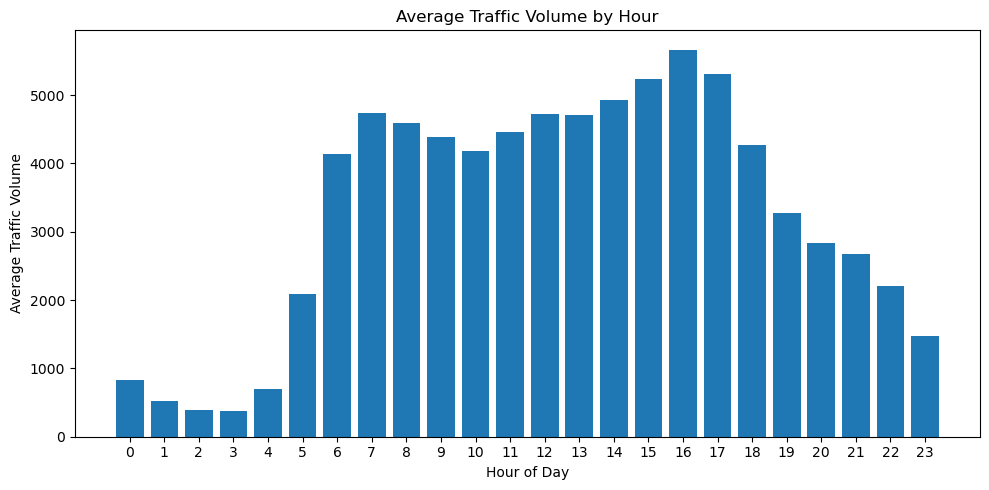

hour
0      834.98
1      516.34
2      388.35
3      371.09
4      702.55
5     2094.57
6     4140.50
7     4740.18
8     4587.50
9     4385.28
10    4184.14
11    4465.57
12    4718.03
13    4714.65
14    4931.89
15    5240.46
16    5663.76
17    5310.08
18    4263.56
19    3275.21
20    2834.67
21    2668.94
22    2199.41
23    1469.14
Name: traffic_volume, dtype: float64

In [19]:
#Load the saved feature data for visualisation.
plot_data = pd.read_csv(
    "data/traffic_features.csv",
    keep_default_na=False,
    parse_dates=["date_time"]
)

# Calculate averge recorded traffic volume for each hour.
hourly_traffic = (
    plot_data.groupby("hour")["traffic_volume"]
    .mean()
    .reindex(range(24))
)

# Create the hourly traffic chart.
chart, ax = plt.subplots(figsize=(10, 5))

ax.bar(hourly_traffic.index, hourly_traffic.values)
ax.set_title("Average Traffic Volume by Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Traffic Volume")
ax.set_xticks(range(24))

chart.tight_layout()

# Save the chart and log its path.
chart_path = Path("charts/traffic_by_hour.png")
chart_path.parent.mkdir(parents=True, exist_ok=True)
chart.savefig(chart_path, dpi=150)

logger.info("Chart saved to %s.", chart_path.as_posix())

plt.show()
plt.close(chart)


display(hourly_traffic.round(2))

Average traffic volume is lowest during the early morning, around 02:00–03:00. It rises sharply between 05:00 and 07:00 and stays relatively high during the daytime. The highest average occurs at 16:00, followed by a decline into the evening. 

2026-10-10 16:15:10,765 | INFO | __main__ | Chart is saved to charts/weekday_weekend_traffic.png.


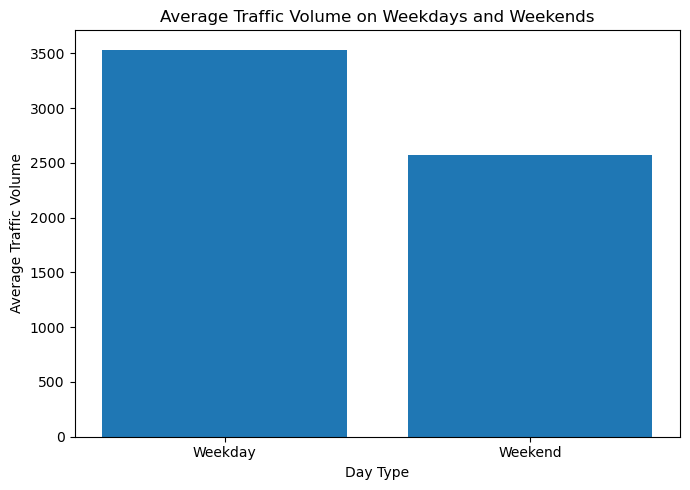

Weekday    3533.29
Weekend    2570.70
Name: traffic_volume, dtype: float64

In [20]:
# Compare average recorded traffic on weekdays and weekends.
weekend_traffic = (
    plot_data.groupby("is_weekend")["traffic_volume"]
    .mean()
    .reindex([0, 1])
)
weekend_traffic.index = ["Weekday", "Weekend"]

# Create the comparison chart.
chart, ax = plt.subplots(figsize=(7, 5))

ax.bar(weekend_traffic.index, weekend_traffic.values)
ax.set_title("Average Traffic Volume on Weekdays and Weekends")
ax.set_xlabel("Day Type")
ax.set_ylabel("Average Traffic Volume")

chart.tight_layout()

# Save the chart and log its path.
chart_path = Path("charts/weekday_weekend_traffic.png")
chart_path.parent.mkdir(parents=True, exist_ok=True)
chart.savefig(chart_path, dpi=150)

logger.info("Chart is saved to %s.", chart_path.as_posix())

plt.show()
plt.close(chart)


display(weekend_traffic.round(2))

Average recorded traffic volume is higher on weekdays than weekends by about 963 vehicles per hour. This is consistent with regular work and school travel, although the chart does not prove the reason for the differe nce. 

2026-10-10 16:16:54,804 | INFO | __main__ | Chart is saved to charts/traffic_by_weather.png.


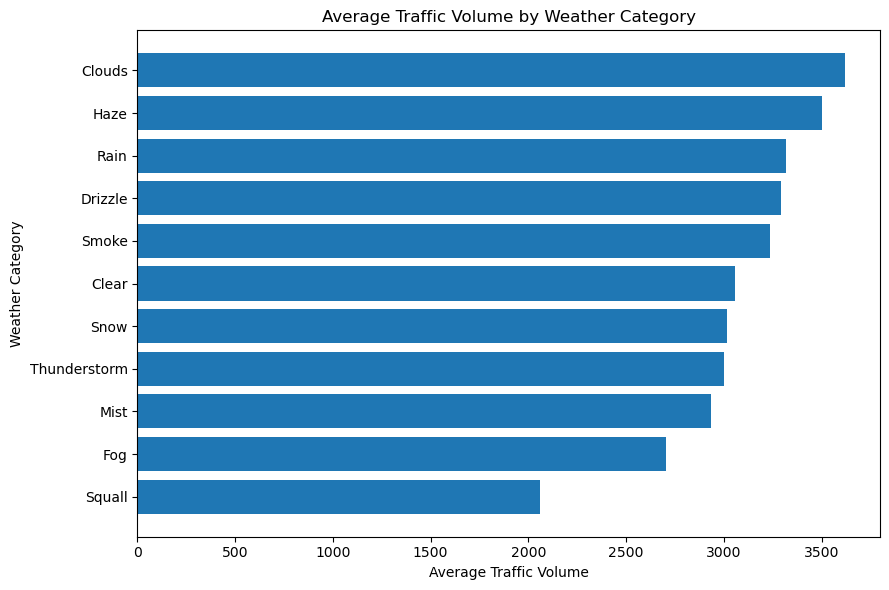

,average_traffic,records
weather_main,,
Squall,2061.75,4
Fog,2703.72,912
Mist,2933.34,5949
Thunderstorm,2999.43,1033
Snow,3016.32,2875
Clear,3055.61,13384
Smoke,3237.65,20
Drizzle,3292.19,1820
Rain,3317.91,5672


In [21]:
#Calculate the average traffic and record count for each weather category.
weather_summary = (
    plot_data.groupby("weather_main")["traffic_volume"]
    .agg(average_traffic="mean", records="size")
    .sort_values("average_traffic")
)

# Create a horizontal chart so the category names are readable.
chart, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    weather_summary.index,
    weather_summary["average_traffic"]
)
ax.set_title("Average Traffic Volume by Weather Category")
ax.set_xlabel("Average Traffic Volume")
ax.set_ylabel("Weather Category")

chart.tight_layout()

#Save the chart
chart_path = Path("charts/traffic_by_weather.png")
chart_path.parent.mkdir(parents=True, exist_ok=True)
chart.savefig(chart_path, dpi=150)

logger.info("Chart is saved to %s.", chart_path.as_posix())

plt.show()
plt.close(chart)


display(weather_summary.round({"average_traffic": 2}))

Clouds has the highest average recorded traffic volume at 3617.99, while Squall has the lowest at 2061.75. However, Squall has only 4 records, compared with 15158 for Clouds, so its average provides limited evidence of a general pattern. Smoke also has few records. 

In [22]:
%%writefile visualizations.py

# Task 3: Visualise Traffic Patterns


import logging
from pathlib import Path

import matplotlib

# Save charts without opening a window 
matplotlib.use("Agg")

import matplotlib.pyplot as plt
import pandas as pd

from pipeline import configure_logging
from feature_engineering import validate_features

logger = logging.getLogger(__name__)

BASE_DIR = Path(__file__).resolve().parent


#Load and check the saved feature data.

def load_feature_data(file_path):
    data = pd.read_csv(
        file_path,
        keep_default_na=False,
        parse_dates=["date_time"]
    )

    validate_features(data)

    logger.info(
        "Chart data has loaded. There are %s rows and %s columns.",
        data.shape[0],
        data.shape[1]
    )

    return data


# Save each chart

def save_chart(chart, filename):
    chart_path = BASE_DIR / "charts" / filename
    chart_path.parent.mkdir(parents=True, exist_ok=True)

    try:
        chart.tight_layout()
        chart.savefig(chart_path, dpi=150)

        logger.info(
            "Chart is saved to %s.",
            chart_path.relative_to(BASE_DIR).as_posix()
        )
    finally:
        plt.close(chart)

Writing visualizations.py


In [23]:
%%writefile -a visualizations.py


# Create a chart of average recorded traffic by hour.
def chart_traffic_by_hour(data):
    hourly_traffic = (
        data.groupby("hour")["traffic_volume"]
        .mean()
        .reindex(range(24))
    )

    chart, ax = plt.subplots(figsize=(10, 5))

    ax.bar(hourly_traffic.index, hourly_traffic.values)
    ax.set_title("Average Traffic Volume by Hour")
    ax.set_xlabel("Hour of Day")
    ax.set_ylabel("Average Traffic Volume")
    ax.set_xticks(range(24))

    # Save the chart.
    save_chart(chart, "traffic_by_hour.png")

    return hourly_traffic

Appending to visualizations.py


In [24]:
%%writefile -a visualizations.py


# Compare average traffic on weekdays and weekends.
def chart_weekday_weekend(data):
    weekend_traffic = (
        data.groupby("is_weekend")["traffic_volume"]
        .mean()
        .reindex([0, 1])
    )
    weekend_traffic.index = ["Weekday", "Weekend"]

    chart, ax = plt.subplots(figsize=(7, 5))

    ax.bar(weekend_traffic.index, weekend_traffic.values)
    ax.set_title("Average Traffic Volume on Weekdays and Weekends")
    ax.set_xlabel("Day Type")
    ax.set_ylabel("Average Traffic Volume")

    save_chart(chart, "weekday_weekend_traffic.png")

    return weekend_traffic


# Compare weather averages and keep record counts for interpretation.
def chart_traffic_by_weather(data):
    weather_summary = (
        data.groupby("weather_main")["traffic_volume"]
        .agg(average_traffic="mean", records="size")
        .sort_values("average_traffic")
    )

    chart, ax = plt.subplots(figsize=(9, 6))

    ax.barh(
        weather_summary.index,
        weather_summary["average_traffic"]
    )
    ax.set_title("Average Traffic Volume by Weather Category")
    ax.set_xlabel("Average Traffic Volume")
    ax.set_ylabel("Weather Category")

    save_chart(chart, "traffic_by_weather.png")

    return weather_summary

Appending to visualizations.py


In [25]:
%%writefile -a visualizations.py


#Load the feature data and create all three charts.
def run_visualizations():
    input_path = BASE_DIR / "data" / "traffic_features.csv"
    data = load_feature_data(input_path)

    # Each chart function saves its output and logs the path.
    hourly_traffic = chart_traffic_by_hour(data)
    weekend_traffic = chart_weekday_weekend(data)
    weather_summary = chart_traffic_by_weather(data)

    logger.info("All three traffic charts have saved.")

    # Return the summaries for use.
    return {
        "hourly_traffic": hourly_traffic,
        "weekend_traffic": weekend_traffic,
        "weather_summary": weather_summary
    }

Appending to visualizations.py


In [26]:
%%writefile -a visualizations.py


# Configure loggin
def main():
    import argparse

    parser = argparse.ArgumentParser(
        description="Create Traffic Charts."
    )
    parser.add_argument(
        "--debug",
        action="store_true",
        help="Include detailed DEBUG messages."
    )
    args = parser.parse_args()

    try:
        configure_logging(debug=args.debug)
        logger.info("Traffic visualisation has started.")

        run_visualizations()

        logger.info("Traffic visualisation has completed successfully.")
        return 0

    except (
        OSError,
        UnicodeError,
        ValueError,
        TypeError,
        KeyError,
        pd.errors.ParserError
    ):
        logger.error(
            "Traffic visualisation could not be completed.",
            exc_info=True
        )
        return 1




if __name__ == "__main__":
    raise SystemExit(main())

Appending to visualizations.py


In [27]:
%%writefile traffic_app.py

# Task 4: Build a Mini Traffic Analytics Application.
import argparse
import logging
from pathlib import Path

import pandas as pd

from pipeline import (
    configure_logging,
    validate_schema,
    validate_cleaned_data
)
from feature_engineering import validate_features

logger = logging.getLogger(__name__)

BASE_DIR = Path(__file__).resolve().parent


# HAndle invalid command arguments
class TrafficArgumentParser(argparse.ArgumentParser):
    def error(self, message):
        raise ValueError(f"Invalid command arguments: {message}.")


#Load and check the processed data before answering a command.
def load_app_data():
    input_path = BASE_DIR / "data" / "traffic_features.csv"

    data = pd.read_csv(
        input_path,
        keep_default_na=False
    )

    validate_schema(data)

    #Invalid dates become missing values and fail validation.
    data["date_time"] = pd.to_datetime(
        data["date_time"],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

    validate_cleaned_data(data)
    validate_features(data)

    logger.info(
        "Application data has been loaded. There are %s rows and %s columns.",
        data.shape[0],
        data.shape[1]
    )

    return data

Writing traffic_app.py


In [28]:
%%writefile -a traffic_app.py


#Find traffic records for a specific date and time.
def query_datetime(data, date_time_text):
    from datetime import datetime

   
    try:
        requested_time = datetime.strptime(
            date_time_text,
            "%Y-%m-%d %H:%M:%S"
        )
    except ValueError:
        raise ValueError(
            "Use a valid date and time in YYYY-MM-DD HH:MM:SS format."
        ) from None

    matching_rows = data.loc[
        data["date_time"] == requested_time,
        [
            "date_time",
            "traffic_volume",
            "traffic_category",
            "weather_main",
            "weather_description",
            "temp",
            "rain_1h",
            "snow_1h"
        ]
    ]

   
    if matching_rows.empty:
        print("No records were found for that date and time.")
    else:
        print(matching_rows.to_string(index=False))

Appending to traffic_app.py


In [1]:
%%writefile -a traffic_app.py


# Identify records above the requested traffic-volume threshold.

def query_high_traffic(data, threshold):
    if threshold < 0:
        raise ValueError("The traffic threshold must be zero or greater.")

    matching_rows = data.loc[
        data["traffic_volume"] > threshold,
        [
            "date_time",
            "traffic_volume",
            "traffic_category",
            "weather_main"
        ]
    ].sort_values("traffic_volume", ascending=False)

    if matching_rows.empty:
        print("No records were found above that traffic threshold.")
    else:
        print(matching_rows.to_string(index=False))

Appending to traffic_app.py


In [2]:
%%writefile -a traffic_app.py

#Compare average traffic volume on weekdays and weekends.
def compare_days(data):
    summary = (
        data.groupby("is_weekend")["traffic_volume"]
        .agg(average_traffic="mean", records="size")
        .reindex([0, 1])
    )

    summary.index = ["Weekday", "Weekend"]
    summary.index.name = "day_type"

    print(summary.round({"average_traffic": 2}).to_string())

Appending to traffic_app.py


In [3]:
%%writefile -a traffic_app.py

#Defin the application's commands and arguments.

def build_parser():
    parser = TrafficArgumentParser(
        description="Query and compare traffic data."
    )
    parser.add_argument(
        "--debug",
        action="store_true",
        help="Include detailed DEBUG messages."
    )

    commands = parser.add_subparsers(
        dest="command",
        required=True
    )

    date_command = commands.add_parser(
        "query",
        help="Find records for a specific date and time."
    )
    date_command.add_argument(
        "--datetime",
        required=True,
        help="Date and time in YYYY-MM-DD HH:MM:SS format."
    )

    traffic_command = commands.add_parser(
        "high-traffic",
        help="Find records above a traffic-volume threshold."
    )
    traffic_command.add_argument(
        "--threshold",
        type=int,
        required=True,
        help="A traffic-volume threshold of zero or greater."
    )

    commands.add_parser(
        "compare-days",
        help="Compare average weekday and weekend traffic."
    )

    return parser

Appending to traffic_app.py


In [4]:
%%writefile -a traffic_app.py

#Run the requested command and handle application errors.
def main():
    import sys

    try:
        configure_logging()
        logger.info(
            "Application is invoked with arguments %s.",
            sys.argv[1:]
        )

        parser = build_parser()
        args = parser.parse_args()

        if args.debug:
            configure_logging(debug=True)

        logger.info(
            "Command %s is invoked with arguments %s.",
            args.command,
            vars(args)
        )

        data = load_app_data()

        if args.command == "query":
            query_datetime(data, args.datetime)
        elif args.command == "high-traffic":
            query_high_traffic(data, args.threshold)
        elif args.command == "compare-days":
            compare_days(data)

        logger.info("Traffic application command has completed successfully.")
        return 0

    except (
        OSError,
        UnicodeError,
        ValueError,
        TypeError,
        KeyError,
        pd.errors.ParserError
    ) as error:
        logger.error("Traffic application could not complete: %s.", error)
        return 1


if __name__ == "__main__":
    raise SystemExit(main())

Appending to traffic_app.py
